# Week 10 — CT Artifacts

Real CT images are rarely perfect. This notebook simulates the artifacts discussed in class and shows
**why** they arise and **which go away with more projections** and which do not.

1. **Metal / high-density** → **streak & star** artifacts (persist no matter how many views).
2. **Beam hardening** → **cupping** (a uniform dense object looks darker in the middle).
3. **Motion** → blurring / ghosting from inconsistent projections.
4. **Ring** artifacts from a miscalibrated detector element.
5. **Photon-counting / thermal noise** → graininess.
6. **Streaks vs stars**: sparse-view streaks vanish with more sweeps; **metal stars do not**.

All use the Shepp–Logan phantom and `skimage`'s `radon`/`iradon` (filtered back-projection).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage.data import shepp_logan_phantom
from skimage.transform import radon, iradon, resize

rng = np.random.default_rng(0)
plt.rcParams["figure.dpi"] = 110

N = 128
yy, xx = np.ogrid[:N, :N]
inside = np.hypot(xx - N // 2, yy - N // 2) < N // 2        # reconstruction circle
phantom = resize(shepp_logan_phantom(), (N, N), anti_aliasing=True) * inside
theta = np.arange(0.0, 180.0, 1.0)

def fbp(sino, th=theta):
    return iradon(sino, theta=th, filter_name="ramp", circle=True)

clean = fbp(radon(phantom, theta=theta, circle=True))
print(f"phantom {phantom.shape}, {len(theta)} projection angles")

phantom (128, 128), 180 projection angles


## 1. Metal / high-density → streak & star artifacts

A tiny **very dense** object (a pacemaker lead, dental filling, surgical clip) attenuates almost all
photons along rays that cross it. Those projection values are huge and inconsistent, so filtered
back-projection smears bright/dark **streaks** radiating from the metal — the classic **star**
artifact. Crucially, this is a *data* problem, so adding more views does **not** remove it.

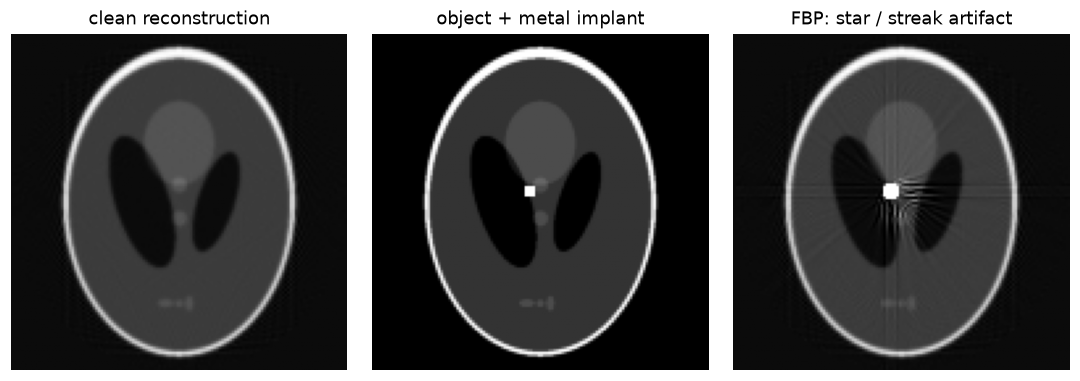

In [2]:
metal = phantom.copy()
metal[58:62, 58:62] = 8.0                 # dense metal implant near the center
recon_metal = fbp(radon(metal, theta=theta, circle=True))

fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
ax[0].imshow(clean, cmap="gray"); ax[0].set_title("clean reconstruction"); ax[0].axis("off")
ax[1].imshow(metal, cmap="gray", vmax=1.0); ax[1].set_title("object + metal implant"); ax[1].axis("off")
ax[2].imshow(recon_metal, cmap="gray", vmin=clean.min(), vmax=clean.max())
ax[2].set_title("FBP: star / streak artifact"); ax[2].axis("off")
plt.tight_layout(); plt.show()

## 2. Beam hardening → cupping

An X-ray beam is **polyenergetic**: low-energy photons are absorbed first, so the beam gets *harder*
(higher mean energy, lower $\mu$) as it passes through tissue. The measured log-attenuation is then
**not** linear in thickness, and a *uniform* dense object reconstructs with a **cupped** profile —
darker in the middle than at the edges. A monochromatic beam would be perfectly flat.

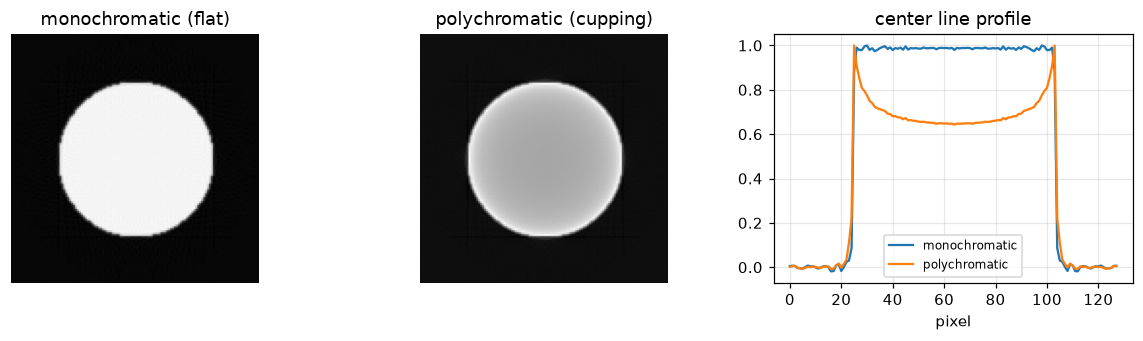

In [3]:
disk = (np.hypot(xx - N // 2, yy - N // 2) < 40).astype(float)   # uniform dense disk
L = radon(disk, theta=theta, circle=True)                        # path length through the disk

E = np.linspace(40, 120, 40)                                     # keV
S = np.clip(120 - E, 0, None) * np.exp(-((30 / E) ** 2)); S /= S.sum()   # X-ray spectrum
mu_E = 0.02 + 6e4 / E ** 3                                       # mu decreases with energy

I = sum(s * np.exp(-m * L) for s, m in zip(S, mu_E))             # polychromatic transmission
recon_poly = fbp(-np.log(I))                                     # beam-hardened reconstruction
recon_mono = fbp((S * mu_E).sum() * L)                           # monochromatic reference

row = N // 2
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].imshow(recon_mono, cmap="gray"); ax[0].set_title("monochromatic (flat)"); ax[0].axis("off")
ax[1].imshow(recon_poly, cmap="gray"); ax[1].set_title("polychromatic (cupping)"); ax[1].axis("off")
ax[2].plot(recon_mono[row] / recon_mono[row].max(), label="monochromatic")
ax[2].plot(recon_poly[row] / recon_poly[row].max(), label="polychromatic")
ax[2].set_title("center line profile"); ax[2].set_xlabel("pixel"); ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3. Motion artifacts

FBP assumes the object is **static** across the whole scan. If the patient (or heart, or breathing)
moves between projection angles, the projections are **inconsistent** and the reconstruction shows
**blurring, doubling, and ghost edges**. Here we shift the phantom by a time-varying amount as each
angle is acquired.

/Users/prahladmenon/Documents/Pitt/1340-2340--2026/.venv/lib/python3.12/site-packages/skimage/transform/radon_transform.py:74: UserWarning: Radon transform: image must be zero outside the reconstruction circle
  warn(


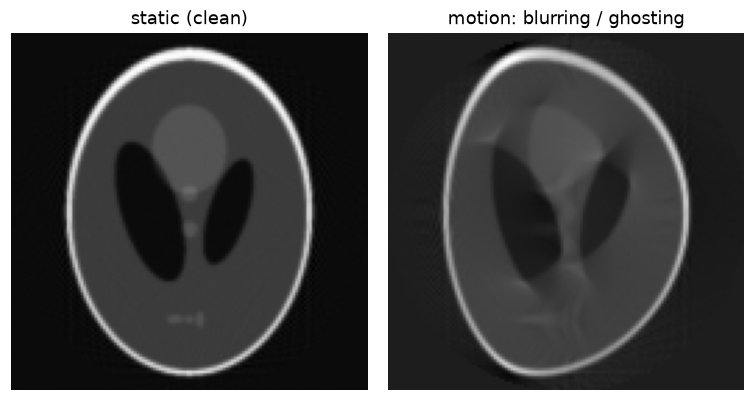

In [4]:
sino_motion = np.zeros_like(radon(phantom, theta=theta, circle=True))
for i, a in enumerate(theta):
    shift = 5.0 * np.sin(2 * np.pi * i / len(theta))      # object drifts during the scan
    moved = ndi.shift(phantom, (shift, 0), order=1)
    sino_motion[:, i] = radon(moved, theta=[a], circle=True)[:, 0]
recon_motion = fbp(sino_motion)

fig, ax = plt.subplots(1, 2, figsize=(7, 3.6))
ax[0].imshow(clean, cmap="gray"); ax[0].set_title("static (clean)"); ax[0].axis("off")
ax[1].imshow(recon_motion, cmap="gray"); ax[1].set_title("motion: blurring / ghosting"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 4. Ring artifacts

In a third-generation scanner each detector element always reads the **same radius**. If one element
is **miscalibrated** (a constant gain/offset error across all angles), that error back-projects into a
perfect **concentric ring**. We simulate it by scaling one detector row of the sinogram.

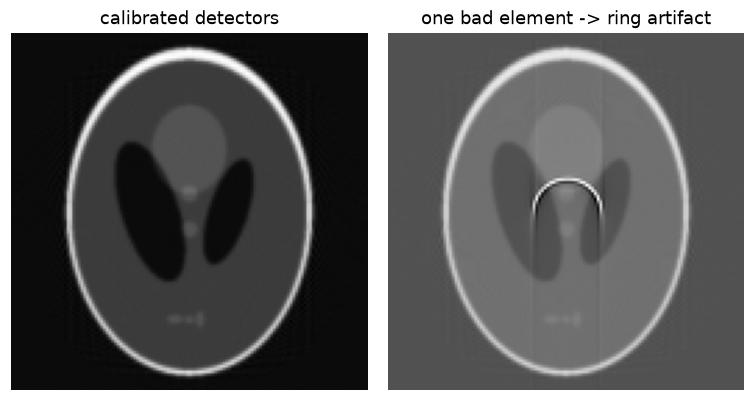

In [5]:
sino_ring = radon(phantom, theta=theta, circle=True).copy()
sino_ring[N // 2 + 12, :] *= 1.4            # one detector element reads 40% high at every angle
recon_ring = fbp(sino_ring)

fig, ax = plt.subplots(1, 2, figsize=(7, 3.6))
ax[0].imshow(clean, cmap="gray"); ax[0].set_title("calibrated detectors"); ax[0].axis("off")
ax[1].imshow(recon_ring, cmap="gray"); ax[1].set_title("one bad element -> ring artifact"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 5. Photon-counting / thermal noise

Detectors **count photons**; counting is Poisson and worsens with detector temperature (thermal
noise). Fewer incident photons (lower dose) → noisier projections → a **grainy** reconstruction. FBP's
ramp filter amplifies this high-frequency noise.

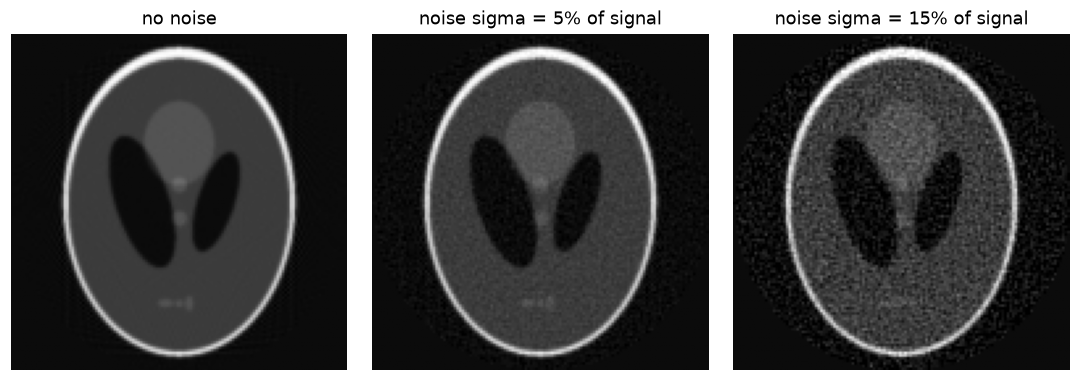

In [7]:
sino = radon(phantom, theta=theta, circle=True)
noise_unit = sino.std()                          # scale noise to the sinogram

fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
ax[0].imshow(clean, cmap="gray"); ax[0].set_title("no noise"); ax[0].axis("off")
for a, frac in zip(ax[1:], [0.05, 0.15]):
    noisy = sino + rng.normal(0.0, frac * noise_unit, size=sino.shape)   # zero-mean detector noise
    recon_noisy = fbp(noisy)
    a.imshow(recon_noisy, cmap="gray", vmin=clean.min(), vmax=clean.max())
    a.set_title(f"noise sigma = {frac:.0%} of signal"); a.axis("off")
plt.tight_layout(); plt.show()

## 6. Which artifacts disappear with more views?

Sparse-view **streaks** come from *missing* angles, so they **fade** as you add projections. A
**metal star** comes from *corrupted* data, so it **persists** even with a full set of angles — a key
distinction from class.

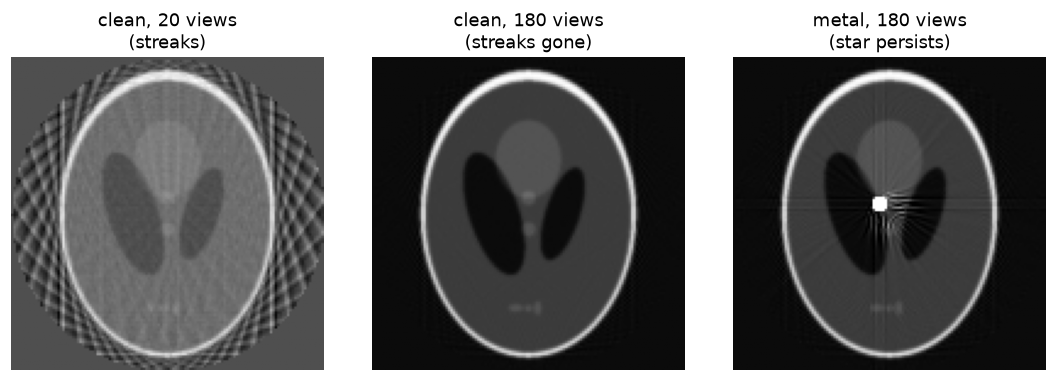

In [8]:
few = np.linspace(0.0, 180.0, 20, endpoint=False)
recon_few = iradon(radon(phantom, theta=few, circle=True), theta=few, filter_name="ramp", circle=True)
recon_full = clean
recon_metal_full = fbp(radon(metal, theta=theta, circle=True))

fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
ax[0].imshow(recon_few, cmap="gray"); ax[0].set_title("clean, 20 views\n(streaks)"); ax[0].axis("off")
ax[1].imshow(recon_full, cmap="gray"); ax[1].set_title("clean, 180 views\n(streaks gone)"); ax[1].axis("off")
ax[2].imshow(recon_metal_full, cmap="gray", vmin=clean.min(), vmax=clean.max())
ax[2].set_title("metal, 180 views\n(star persists)"); ax[2].axis("off")
plt.tight_layout(); plt.show()

## Takeaways

- **Metal / high-density** objects corrupt the line integrals → **streak / star** artifacts that
  **persist regardless of the number of sweeps** (and cause dark shadows between dense objects).
- **Beam hardening** (polyenergetic beam) makes a uniform dense object reconstruct with **cupping**;
  mitigated by filtration, calibration, or dual-energy CT.
- **Motion** breaks the static-object assumption → **blur / ghosting**; addressed with faster scans,
  gating, or motion correction.
- **Detector miscalibration** → **ring** artifacts (constant error at one radius).
- **Photon-counting / thermal noise** → graininess; worse at **low dose**, amplified by the ramp filter.
- The telltale rule: artifacts from **missing** data (sparse-view streaks) improve with more views;
  artifacts from **corrupted** data (metal, rings, motion) do not.